Saving flower_sample-2.png to flower_sample-2.png
Enter initial window size (odd number, e.g. 3): 3
Enter maximum window size (odd number, e.g. 7): 7
Enter salt-and-pepper noise amount (e.g. 0.05): 0.05

PSNR Comparison
--------------------------
Noisy Image: 18.44992943813122 dB
Median Filter: 34.93047807573534 dB
Adaptive Median Filter: 39.15323185529299 dB


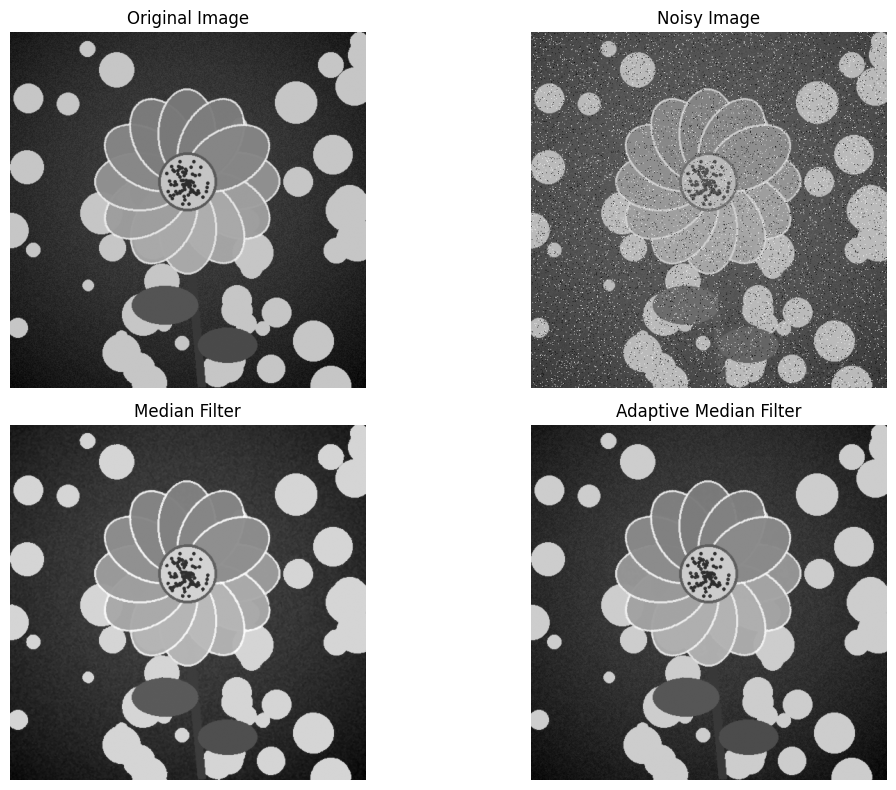

Otsu Threshold Value: 126.0


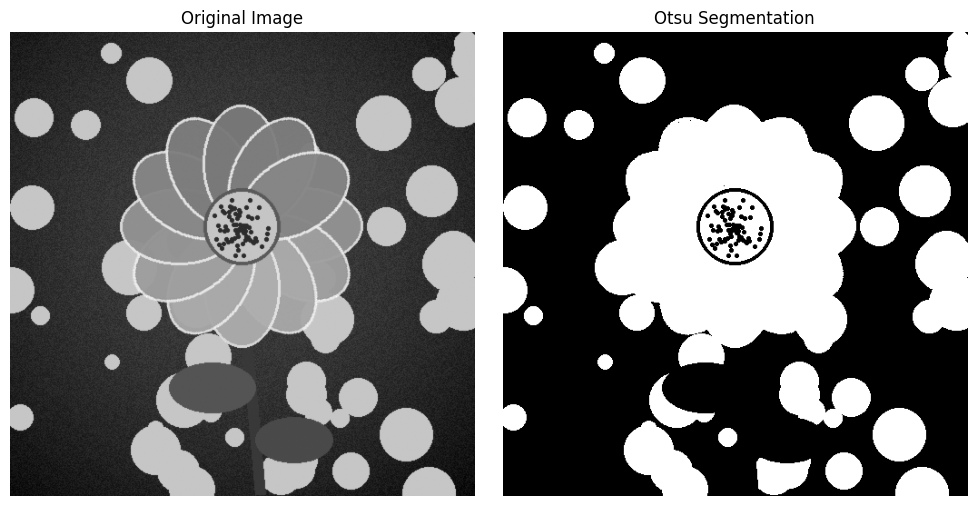

Assignment 10 completed successfully!


In [1]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))

img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

if img is None:
    raise ValueError("Image could not be loaded.")

original = img.copy()

# Q1: Adaptive Median Filtering and PSNR Comparison

Smin = int(input("Enter initial window size (odd number, e.g. 3): "))
Smax = int(input("Enter maximum window size (odd number, e.g. 7): "))
noise_amount = float(input("Enter salt-and-pepper noise amount (e.g. 0.05): "))

if Smin < 3 or Smin % 2 == 0:
    raise ValueError("Smin must be an odd number greater than or equal to 3.")

if Smax < Smin or Smax % 2 == 0:
    raise ValueError("Smax must be odd and greater than or equal to Smin.")

if not 0 <= noise_amount <= 1:
    raise ValueError("Noise amount must be between 0 and 1.")

noisy = original.copy()
random_matrix = np.random.random(original.shape)

noisy[random_matrix < noise_amount / 2] = 0
noisy[(random_matrix >= noise_amount / 2) &
      (random_matrix < noise_amount)] = 255

median_result = cv2.medianBlur(noisy, Smin)

def adaptive_median_filter(image, Smin, Smax):

    rows, cols = image.shape
    output = np.zeros((rows, cols), dtype=np.uint8)

    for i in range(rows):
        for j in range(cols):

            window_size = Smin
            pixel = int(image[i, j])
            result = pixel

            while window_size <= Smax:

                pad = window_size // 2

                r1 = max(0, i - pad)
                r2 = min(rows, i + pad + 1)
                c1 = max(0, j - pad)
                c2 = min(cols, j + pad + 1)

                window = image[r1:r2, c1:c2]

                zmin = int(np.min(window))
                zmax = int(np.max(window))
                zmed = int(np.median(window))

                A1 = zmed - zmin
                A2 = zmed - zmax

                if A1 > 0 and A2 < 0:

                    B1 = pixel - zmin
                    B2 = pixel - zmax

                    if B1 > 0 and B2 < 0:
                        result = pixel
                    else:
                        result = zmed

                    break

                else:
                    window_size += 2

            if window_size > Smax:
                result = zmed

            output[i, j] = result

    return output

adaptive_result = adaptive_median_filter(noisy, Smin, Smax)

def calculate_psnr(original, processed):

    mse = np.mean(
        (original.astype(np.float64) -
         processed.astype(np.float64)) ** 2
    )

    if mse == 0:
        return float("inf")

    return 10 * np.log10((255 ** 2) / mse)

psnr_noisy = calculate_psnr(original, noisy)
psnr_median = calculate_psnr(original, median_result)
psnr_adaptive = calculate_psnr(original, adaptive_result)

print("\nPSNR Comparison")
print("--------------------------")
print("Noisy Image:", psnr_noisy, "dB")
print("Median Filter:", psnr_median, "dB")
print("Adaptive Median Filter:", psnr_adaptive, "dB")

images = [original, noisy, median_result, adaptive_result]

titles = [
    "Original Image",
    "Noisy Image",
    "Median Filter",
    "Adaptive Median Filter"
]

plt.figure(figsize=(12, 8))

for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

# Q2: Otsu's Global Thresholding

threshold_value, otsu_result = cv2.threshold(
    original, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Otsu Threshold Value:", threshold_value)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(otsu_result, cmap="gray")
plt.title("Otsu Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite("Original.png", original)
cv2.imwrite("Noisy.png", noisy)
cv2.imwrite("Median_Filter.png", median_result)
cv2.imwrite("Adaptive_Median_Filter.png", adaptive_result)
cv2.imwrite("Otsu_Segmentation.png", otsu_result)

print("Assignment 10 completed successfully!")
